In [25]:
import numpy as np
import pandas as pd
import optuna
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

# Загрузим данные

- Данные упорядочены по времени
- Задача - предсказать `target`
- Фичи - `feature_i`
- Трейн, валидация и тест уже определены (см. колонку `sample_part`)

In [26]:
df = pd.read_parquet('df.parquet.gzip')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 22620 to 310653
Columns: 235 entries, date to sample_part
dtypes: category(2), datetime64[ms](1), datetime64[ns](2), float64(220), int64(9), object(1)
memory usage: 893.6+ MB


In [27]:
df.head()

,date,month,quarter,feature_217,feature_66,feature_9,feature_193,feature_15,feature_199,feature_25,...,feature_20,feature_188,feature_71,feature_106,feature_14,feature_92,feature_179,feature_102,target,sample_part
22620,2021-01-01,2021-01-01,2021-01-01,1.180855,0.483118,13.976791,1.135021,43.271792,-46.888875,97.558366,...,23.745198,-32.001093,85.489903,1.454045,-195.725786,3.719083,1,-28.813537,0.0,train
478621,2021-01-01,2021-01-01,2021-01-01,3.427814,0.886778,27.158209,-0.378728,80.087863,-67.242703,105.803406,...,22.902111,-37.436243,71.735619,1.657242,-176.250404,3.277817,1,-45.987721,1.0,train
372254,2021-01-01,2021-01-01,2021-01-01,-38.555018,1.227175,19.893873,0.498787,98.464365,-67.402522,81.858076,...,21.848414,-51.872841,65.363236,1.626874,-178.116798,2.028950,0,-31.074122,1.0,train
2596,2021-01-01,2021-01-01,2021-01-01,-14.666558,0.753129,18.203010,-1.200014,117.331340,-25.557745,90.277266,...,26.134586,-49.703003,65.013659,1.170023,-192.232264,2.218177,1,-36.703897,0.0,train
216892,2021-01-01,2021-01-01,2021-01-01,6.734990,1.129100,11.245920,-0.108955,61.205722,-78.397406,82.637472,...,24.201039,-41.070219,69.986127,1.630795,-200.155528,3.055104,1,-44.672299,1.0,train


In [28]:
TARGET = 'target'
N_FEATURES = 230
features = [f'feature_{i}' for i in range(N_FEATURES)]

# Первичный отбор признаков... (1 балл)

**Задание:** Сначала отсеем совсем уж мусорные признаки.

Воспользовавшись вашим кодом для вычисления `IV` из прошлой домашки, для всех **числовых** фичей вычислите `IV` на 20 бакетах. Отсейте признаки с `IV < 0.005`.

**Hint:** паркет не всегда сохраняет `dtype` колонки. Чтобы проверить признаки на "реальный" тип данных, лучше на всякий случай посмотреть на `nunique` 

In [29]:
# your code here
from typing import Union
from scipy.special import logit

def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на 
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets
def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

def calc_IV(
        values : Union[np.ndarray, pd.Series],
        target : Union[np.ndarray, pd.Series],
        n_buckets : int
    ) -> float:
    buckets = calc_buckets(values, n_buckets)
    
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # всё ещё простите за это...

    return IV

In [30]:
# В отдельную ячейку, потому что долго.
num_df_columns = [x for x in df.select_dtypes(include=['float64', 'int64']).columns if df[x].nunique() > 50  ]
target_train = df[TARGET][df['sample_part'] == 'train']
iv_arr = {}

In [31]:
for x in num_df_columns:
    val_raw = df[x][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train, 20)
    iv_arr[x] = iv 

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\series.py:1031: RuntimeWarning:

invalid value encountered in cast



In [32]:
iv_selected_features = [f for f, iv in iv_arr.items() if iv >= 0.005]
print(len(iv_selected_features), iv_selected_features)

57 ['feature_9', 'feature_15', 'feature_154', 'feature_218', 'feature_96', 'feature_223', 'feature_30', 'feature_225', 'feature_162', 'feature_167', 'feature_109', 'feature_124', 'feature_79', 'feature_213', 'feature_117', 'feature_38', 'feature_24', 'feature_75', 'feature_5', 'feature_56', 'feature_114', 'feature_139', 'feature_65', 'feature_142', 'feature_12', 'feature_35', 'feature_227', 'feature_115', 'feature_155', 'feature_132', 'feature_76', 'feature_97', 'feature_140', 'feature_135', 'feature_2', 'feature_46', 'feature_100', 'feature_111', 'feature_138', 'feature_164', 'feature_98', 'feature_36', 'feature_183', 'feature_27', 'feature_156', 'feature_4', 'feature_32', 'feature_206', 'feature_172', 'feature_70', 'feature_44', 'feature_23', 'feature_170', 'feature_39', 'feature_216', 'feature_94', 'feature_43']


**Вопрос**: Почему некорректно сравнивать `IV` у категориальных и числовых фичей?

Вычислите IV для категориальных фичей на `n` бакетах, где `n = min(число категорий фичи, 20)`. Возможно, придётся перекодировать некоторые фичи (*только не OneHot-ом!*)

*Опционально*: примените также и к категориальным фичам предварительный отбор по `IV` с менее строгим порогом

In [33]:
# your code here
cat_df_columns = [x for x in df.select_dtypes(include=['category', 'int64']).columns if df[x].nunique() <= 50 ]
cat_df_columns

['feature_147',
 'feature_144',
 'feature_168',
 'feature_165',
 'feature_31',
 'feature_0',
 'feature_209',
 'feature_222',
 'feature_37',
 'feature_157',
 'feature_179']

In [34]:
iv_selected_cat_features = {}
for y in cat_df_columns:
    val_raw = df[y][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train,  min(20, len(np.unique(val)) ))
    iv_selected_cat_features[y] = iv 

iv_selected_cat_features = [f for f, iv in iv_selected_cat_features.items() if iv >= 0.001]
len(iv_selected_cat_features), iv_selected_cat_features

(6,
 ['feature_147',
  'feature_144',
  'feature_168',
  'feature_165',
  'feature_31',
  'feature_209'])

**Ответ:** сравнивать IV у категориальных и числовых фичей некорректно, потому что мы теряем какую-то часть информации о непрерывных фичах из-за биннинга, потому что мы для корректного подсчёта IV мы должны относиться к ней, как к дискретной случайной величине, а тогда мы можем очень плохо поделить на бакеты, чтобы получить дискретность, и поэтому получить низкий IV, хотя проблема была не в самой фиче, а в разбиении на бакеты, категориальные фичи же в свою очередь от такой проблемы не страдают, потому что уже дискретны, поэтому для них IV не занижается.

# Бустинг

Используйте код для подбора гиперпараметров и обучения бустинга из предыдущей домашки

In [35]:
# В переменную features_optuna положите список признаков с предыдущего шага
features_optuna = iv_selected_features + iv_selected_cat_features
len(features_optuna)

63

In [36]:
import lightgbm as lgb

In [37]:
import optuna

train_data_df = df[df['sample_part'] == 'train']
valid_data_df = df[df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[features_optuna], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[features_optuna], label=valid_data_df[TARGET])

X_test = valid_data_df[features_optuna]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'n_jobs' : -1,
        'random_state': 52,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 12:25:43,715] A new study created in memory with name: no-name-de463d5a-8d83-49de-924e-d623279bbe7d


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[99]	valid_0's auc: 0.736161


[I 2026-08-19 12:25:50,113] Trial 0 finished with value: 0.7361612064108791 and parameters: {'num_leaves': 154, 'learning_rate': 0.10563694915167389, 'feature_fraction': 0.5}. Best is trial 0 with value: 0.7361612064108791.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.715902


[I 2026-08-19 12:26:05,043] Trial 1 finished with value: 0.7159015167557066 and parameters: {'num_leaves': 188, 'learning_rate': 0.021388113771873784, 'feature_fraction': 0.9}. Best is trial 0 with value: 0.7361612064108791.


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.697135


[I 2026-08-19 12:30:25,851] Trial 48 finished with value: 0.6971352102962604 and parameters: {'num_leaves': 174, 'learning_rate': 0.0030215391167481087, 'feature_fraction': 0.5}. Best is trial 41 with value: 0.7393039091792133.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.735174


[I 2026-08-19 12:30:29,720] Trial 49 finished with value: 0.7351736779990287 and parameters: {'num_leaves': 85, 'learning_rate': 0.12450051895625913, 'feature_fraction': 0.6}. Best is trial 41 with value: 0.7393039091792133.


Best params: {'num_leaves': 192, 'learning_rate': 0.08666957166696355, 'feature_fraction': 0.6}
Best AUC: 0.7393039091792133


## Важность признаков (1 балл)

**Задание:** Постойте гистограмму важности признаков по `split` и `gain` для бустинга из предыдущего пункта.

In [38]:
#####
# <your code here>
#####
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_lgb = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_lgb.predict(df[df['sample_part'] == 'test'][features_optuna])))

0.7239271888753497


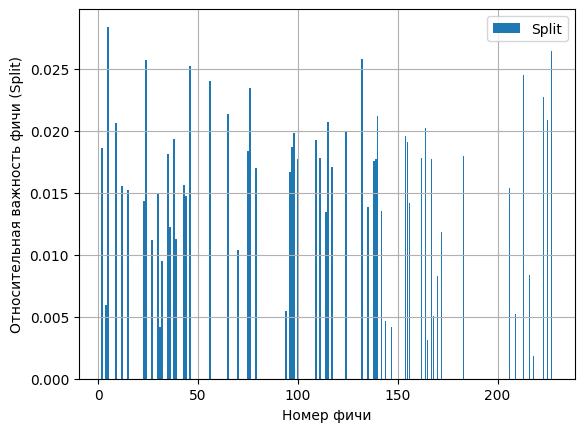

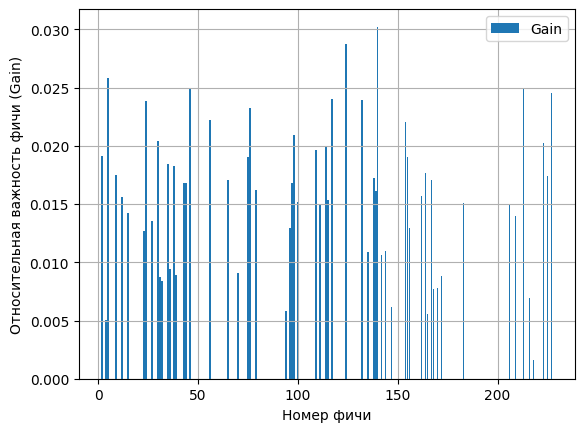

In [45]:
space = [int(feature[-4:].split('_')[1]) for feature in train_data_df[features_optuna].columns]
split_importance = model_lgb.feature_importance(importance_type='split')
plt.bar(space, split_importance / sum(split_importance), label = 'Split')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Split)")
plt.grid()
plt.legend()
plt.show()

gain_importance = model_lgb.feature_importance(importance_type='gain')
plt.bar(space, gain_importance / sum(gain_importance), label = 'Gain')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Gain)")
plt.grid()
plt.legend()
plt.show()

**Вопрос:** Какие выводы можно сделать из полученных графиков?

И по gain, и по split фичи имеют примерно одинаковую важность, отличаются пики, но визуально картина примерно одинаковая: в районе 220 есть признак, у которого наименьшая важность по обоим методам среди других признаков, наибольшую важность по гейну имеет признак в районе 140, когда по сплиту наиболее важный признак находится в районе 10.

# Логрег

## plot_metric_time (1 балл)

**Задание:** Реализуйте функцию plot_metric_time, которая будет принимать на вход четыре аргумента, а именно: 
- массив значений фичи, 
- массив значений таргета,
- массив времени (аггрегированного по месяцам или кварталам, то есть `month` или `quarter` в вашей задаче, по дням рисовать не надо),
- метрику, которую необходимо отрисовать (нужно реализовать функцию для двух метрик: `IV` и `roc_auc`)
- число бакетов для вычисления `IV`, если выбрана эта метрика

Можете добваить какие-то ещё аргументы, если вам нужно

Если в фиче есть пропуски, функция должна убирать строки с пропусками из рассмотрения

**Hint**: можно, конечно, реализовать эту функцию через цикл, а можно попробовать разобраться и реализовать её через пандасовские `groupby` -> `apply`, это изящнее и быстрее

In [40]:
import plotly.graph_objects as go

In [41]:
def plot_metric_time(
        values: pd.Series,
        target: pd.Series,
        time: pd.Series,
        metric: str = 'IV',
        n_buckets_for_IV: int = 15,
        date_or_quarter : str = 'date',
        show_or_return : str = 'show'
) -> go.Figure:
    
    if date_or_quarter not in ['date', 'quarter']:
        raise NotImplementedError("Pass either date or quarter")

    if show_or_return not in ['show', 'return']:
        raise NotImplementedError("Pass either show or return")
    
    feature = values.name
    time.name = date_or_quarter
    values = pd.concat([values, target, time], axis = 1)
    values = values.dropna()
    proper_values = values 

    if metric == 'IV':
        res = proper_values.groupby(by = date_or_quarter).apply(lambda x: calc_IV(x[feature], x['target'], n_buckets_for_IV), include_groups = False)
    elif metric == 'roc_auc':
       res = proper_values.groupby(by = date_or_quarter).apply(lambda x: roc_auc_score(x['target'], x[feature]), include_groups = False)
    else:
        raise NotImplementedError("only 'IV' and 'roc_auc' metrics are implemented")

    # your code here

    plot_title = f'{feature}, {metric} in time'
    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x= res.index, # месяцы или кварталы, your code here
            y= res.values, # аггрегированное значение метрики, your code here
            mode='markers+lines',
            name=feature# имя фичи, your code here
            ))
    fig.update_layout(
            title_text=plot_title,
            yaxis=dict(title=metric),
            width=1000,
            height=450,
            xaxis=dict(
                domain=[0, .95],
                showgrid=True,
                tickvals=res.index  # месяцы или кварталы, your code here
                ),
            margin=dict(l=30, r=30, b=30, t=50),
            )
    if show_or_return == 'show':
        fig.show()
    else:
        return fig

In [42]:
# примерно так это должно будет выглядеть
plot_metric_time(df['feature_52'], df['target'], df['quarter']) 

**Задание:** Возьмите **топ-15** фичей получившегося бустинга по важности по `gain`. Отрисуйте для них графики стабильности по `IV` во времени и удалите из рассмотрения те признаки, качество которых деградирует

**NB!** Обращайте внимание на масштаб оси *y!* Иногда признак стабильнее, чем кажется)

Если вам это мешает, можете поменять ось *y*, чтобы она начиналась от нуля в прошлом задании.

Отрисовывать будем по трейну, потому что, кажется, неправильно, когда мы отбираем на всём датасете, потому что мы получаем информацию из теста и на её основе делаем преобразование, а это уже пахнет утечкой данных, поэтому ограничимся только анализом на трейне, но преобразовывать будем весь признак.

In [46]:
# your code here
top_15_idxs = np.argsort(gain_importance)[-15:]
top_15_features = [features_optuna[idx] for idx in top_15_idxs] [::-1]

In [47]:
for feature in top_15_features: 
    plot_metric_time(train_data_df[feature], target_train, train_data_df['quarter'])

**Список деградирующих фичей:**

132, 223.
Так как остальные признаки либо колеблются, либо держутся примерно в одних и тех же значениях, либо показывают +- стабильный рост, только эти фичи показывает какую-то деградацию.

На этом моменте предлагаю сделать новый маленький датафрейм, чтобы не "портить" исходный

И проводить все манипуляции с фичами на нём

In [214]:
top15features_stable = [feature for feature in top_15_features if feature not in ['feature_132', 'feature_223']]

df_for_logreg = df[top15features_stable + ['date', 'month', 'quarter', 'target', 'sample_part']]
top15features_stable

['feature_140',
 'feature_124',
 'feature_5',
 'feature_46',
 'feature_213',
 'feature_227',
 'feature_117',
 'feature_24',
 'feature_76',
 'feature_56',
 'feature_154',
 'feature_98',
 'feature_30']

## Предобработка признаков (3 балла)

**Задание:** Используя функицю woe_line из ДЗ по логрегу, проверьте **числовые** фичи из полученного списка фичей на линейность по WoE на трейн-выборке (если в фиче есть пропуски - дропаем их при отрисовке)

Если фичи нелинейные, **линеаризуйте их**.

Преобразования, которые можно/стоит пробовать:
- клипы (`np.clip`) - зачастую их достаточно
- корень
- квадрат
- логарифм

Если нужно, можно прибавлять к фиче константу или менять её знак

При желании можно "распилить фичу на две половины" (если она немонотонна) и линеаризовать их по отдельности

Однако слишком упираться в линеаризацию фичей не нужно. Если фича ну совсем никак не линеаризуется, в крайнем случае можно её дропнуть или оставить как есть.

При отрисовке можно ограничиться 15-20 бактеами

In [215]:
# your code here
from typing import Tuple
from sklearn.linear_model import LogisticRegression
import scipy.stats as sps

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"] - buckets_info["woe"],
                arrayminus=buckets_info["woe"] - buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature

    model = LogisticRegression()
    model = model.fit(values.reshape(-1, 1), target) # reshape, иначе ругается sklearn

    # .predict_proba возвращает матрицу (n_samples, n_classes)
    # простыми словами он возращает матрицу вида:
    # (P(y = 0 | x_1), P(y = 1 | x_1))
    # (...)
    # (P(y = 0 | x_n), P(y = 1 | x_n))
    # Так как в логреге мы интересуемся P(y = 1 | X), 
    # то и берём мы только второй столбец.

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float) -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate, badrate_lower, badrate_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
        badrate[bucket] = target[buckets == bucket].mean()
        add_val = sps.norm.ppf(1 - 0.05 / 2, loc = 0, scale = 1) * ((badrate[bucket]) * (1 - badrate[bucket]) / len(target[buckets == bucket]))**0.5
        badrate_lower[bucket] =  badrate[bucket] - add_val
        badrate_upper[bucket] =  badrate[bucket] + add_val

    # переходим от бэдрейта к woe
    woe, woe_lower, woe_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
            woe[bucket] = woe_transform(badrate=badrate[bucket], offset=offset)
            woe_lower[bucket] = woe_transform(badrate = badrate_lower[bucket], offset = offset)
            woe_upper[bucket] = woe_transform(badrate = badrate_upper[bucket], offset=offset)
    return woe, woe_lower, woe_upper

def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""

    mean_feature = np.array([values[buckets == i].mean() for i in sorted(set(buckets))])
    offset = logit(target.mean())
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : calc_line(values, target, mean_feature, offset),
        "woe"          : woe,
        "woe_lower"    : woe_lower,
        "woe_upper"    : woe_upper
    }

    return buckets_info

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # простите за это..

    # Взвешенный R^2 
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете

    # Будем считать как квадрат корреляции, потому что здесь -
    # https://en.wikipedia.org/wiki/Coefficient_of_determination
    # - так написано, а кто я такой, чтобы не верить?

    X_arr = []
    w_arr = []
    woe_buck, _, _ = woe_ci(target, buckets, offset)
    woe_buck = np.asarray(woe_buck)
    
    for i in sorted(set(buckets)):
        bucket = target[buckets == i]
        X_arr.append(values[buckets == i].mean())
        w_arr.append(len(bucket))

    w_arr = np.array(w_arr)
    X_arr = np.array(X_arr)

    w_s = w_arr.sum()
    X_w_mean = np.sum([w_arr[i] * X_arr[i] for i in range(len(set(buckets)))]) / w_s
    Y_w_mean = np.sum([w_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s

    X_arr = X_arr - X_w_mean
    woe_buck = woe_buck - Y_w_mean

    cov = np.sum([w_arr[i] * X_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s
    var_x = np.sum([w_arr[i] * X_arr[i] ** 2 for i in range(len(set(buckets)))]) / w_s
    var_y = np.sum([w_arr[i] * woe_buck[i] ** 2 for i in range(len(set(buckets)))]) / w_s

    R_sqr = cov ** 2 / (var_x * var_y)

    plot_title = (        
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

In [216]:
for x in top15features_stable:
    print(train_data_df[x].dtype, x)

float64 feature_140
float64 feature_124
float64 feature_5
float64 feature_46
float64 feature_213
float64 feature_227
float64 feature_117
float64 feature_24
float64 feature_76
float64 feature_56
float64 feature_154
float64 feature_98
float64 feature_30


Видимо придётся проверять все..)

In [217]:
for x in top15features_stable:
    val = train_data_df[x].dropna()
    print(x)
    woe_line(np.asarray(val), np.asarray(target_train[val.index]), 15).show()

feature_140


feature_124


feature_5


feature_46


feature_213


...

feature_76


feature_56


feature_154


feature_98


feature_30


Фичи, которые не надо линеаризовать:

117, 24, 98 - уже лучше, чем ничего, итого под линеаризацию попадут 10 фичей.

In [218]:
lin_cand_features = [feature for feature in top15features_stable if feature not in ['feature_117', 'feature_24', 'feature_98']]
print(len(lin_cand_features), df_for_logreg.head())
logreg_train = df_for_logreg[df_for_logreg['sample_part'] == 'train']
logreg_test = df_for_logreg[df_for_logreg['sample_part'] == 'test']
logreg_train_target = logreg_train['target']
logreg_test_target = logreg_test['target']

10         feature_140  feature_124   feature_5  feature_46  feature_213  \
22620          15.0   -61.495238 -215.945717  115.319640     7.458468   
478621         28.0   -28.477404 -170.713568  172.981221    10.884534   
372254         10.0          NaN -154.503339 -119.580242    17.206131   
2596           22.0   -42.117574 -131.553444   85.009499    18.618423   
216892         50.0   -48.599477 -162.092621   43.108790     8.274292   

        feature_227  feature_117  feature_24  feature_76  feature_56  \
22620   -173.334454   -17.226707   -7.179830   24.511627 -258.724816   
478621  -479.616136    -8.564242  -23.797875 -131.928627  -75.131292   
372254  -222.993621   -10.249472  -22.976857 -130.156221 -270.127459   
2596     312.396421   -13.114987  -14.087877   20.596559 -463.492274   
216892  -201.997489    -7.378194  -17.195954  178.124940  327.178077   

        feature_154  feature_98  feature_30       date      month    quarter  \
22620      0.354745   15.141825    0.036732 2

**Линеаризация.**

1)

In [219]:
val = logreg_train[lin_cand_features[0]].dropna()
print(lin_cand_features[0])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_140


Похоже на ветвь параболы, попробуем квадрат, но накинем на него ещё клиппинг сверху, чтобы точно попасть в нужные значения. Помним, что такой специальный квадрат особо не перемешивает информацию, особенно в совокупности с тем, что средние всех бинов у нас строго положительны.

In [220]:
print("Train:")
val = logreg_train[lin_cand_features[0]].dropna()
val = (np.sign(val) * val ** 2).clip(lower = 400)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[0]].dropna()
val = (np.sign(val) * val ** 2).clip(lower = 400)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Информативность фичи по IV не упала, но видно, что местами значения стали более шумными, особенно этот гигант между 2000 и 2500, скорее всего в этот бин просто попадает мало значений, но так как метрики вполне приемлемые, нас это устраивает. Переобучения тут тоже нет, на тесте $R^2$ просел, но IV повыше.

In [221]:
df_for_logreg.loc[:, lin_cand_features[0]] = (np.sign(df_for_logreg[lin_cand_features[0]]) * (df_for_logreg[lin_cand_features[0]])**2).clip(lower = 400)

In [222]:
val = df_for_logreg[lin_cand_features[0]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

2) 

In [223]:
val = logreg_train[lin_cand_features[1]].dropna()
print(lin_cand_features[1])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_124


Клипы здесь плохо себя показали: либо мы клипуем слишком сильно, из-за чего IV падает, а шум возрастает, либо мы ничего от этого не получаем, кроме ухудшения всех метрик. Возможно это потому, что распределение у фичи такое, что всё полезная информация находится в хвостах, которые мы клипами отсекаем, оставляя только шум. Поэтому попробуем что-то покруче, например, $sign(x) x^2$, потому что график похож на какую-то ветвь параболы, причём во всех бинах среднее получилось строго отрицательным, но мы на всякий случай всё равно сохраним знак, чтобы сильно не перемешивать информацию.

In [224]:
print("Train:")
val = logreg_train[lin_cand_features[1]].dropna()
val = np.sign(val) * val ** 2
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[1]].dropna()
val = np.sign(val) * val ** 2
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Джекпот! Информативность по IV не потеряли, roc-auc остался тем же, при этом по $R^2$ мы стали линейны! Квадрат здесь ничего не портит, так как во всех бинах среднее были отрицательными, поэтому, так как мы сохранили знак, то ничего критичного это отображение с нашими данными не сделала, сильно информацию мы не перемешали. Причём на тесте метрики даже лучше, так что едва ли тут можно судить о каком-то переобучении с таким отображением. 

In [225]:
df_for_logreg.loc[:, lin_cand_features[1]] = np.sign(df_for_logreg[lin_cand_features[1]]) * (df_for_logreg[lin_cand_features[1]])**2

In [226]:
val = df_for_logreg[lin_cand_features[1]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

3)

In [227]:
val = logreg_train[lin_cand_features[2]].dropna()
print(lin_cand_features[2])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_5


Тут попробуем что-то получить при помощи логарифма с правильным знаком и клипинга, в конце накинем косметический минус, чтобы сделать всё обратно отрицательным.

In [228]:
print("Train:")
val = logreg_train[lin_cand_features[2]].dropna()
val = -np.log(np.abs(val)).clip(upper = 5.1)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[2]].dropna()
val = -np.log(np.abs(val)).clip(upper = 5.1)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Конечно, очень жаль, что у нас не получилось прям совсем крутых метрик на тесте, но это тоже неплохо, мы хотя бы не переобучились.

In [229]:
df_for_logreg.loc[:, lin_cand_features[2]] = -np.log(np.abs(df_for_logreg[lin_cand_features[2]])).clip(upper = 5.1)

In [230]:
val = df_for_logreg[lin_cand_features[2]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

4)

In [231]:
val = logreg_train[lin_cand_features[3]].dropna()
print(lin_cand_features[3])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_46


Похоже на какую-то повёрнутую параболу, поэтому попробуем квадрат вместе с клипом.

In [232]:
print("Train:")
val = logreg_train[lin_cand_features[3]].dropna()
val = (val ** 2).clip(upper = 125_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[3]].dropna()
val = (val ** 2).clip(upper = 125_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Мы хороошо линеаризовали фичу, но вместе с этими потеряли в информативности самой фичи, так как IV упал с 0.015 до 0.01, но так как это всё ещё больше нашей мусорной границы в 0.005, то нас это устраивает.

In [233]:
df_for_logreg.loc[:, lin_cand_features[3]] = (df_for_logreg[lin_cand_features[3]] ** 2).clip(upper = 125_000)

In [234]:
val = df_for_logreg[lin_cand_features[3]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

5) 

In [235]:
val = logreg_train[lin_cand_features[4]].dropna()
print(lin_cand_features[4])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_213


Казалось бы, что очень похоже на то, что у нас уже было, но никакие из выше указанных функций не подходят, кроме $\frac{1}{x}$, поэтому возьмём её вместе с клипом.

In [236]:
print("Train:")
val = logreg_train[lin_cand_features[4]].dropna()
val = (1 / val).clip(lower = 0.08, upper = 0.25)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[4]].dropna()
val = (1 / val).clip(lower = 0.08, upper = 0.25)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Опять же, не прям идеально, но уже неплохо.


In [237]:
df_for_logreg.loc[:, lin_cand_features[4]] = (1 / df_for_logreg[lin_cand_features[4]]).clip(lower = 0.08, upper = 0.25)

In [238]:
val = df_for_logreg[lin_cand_features[4]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

6)

In [239]:
val = logreg_train[lin_cand_features[5]].dropna()
print(lin_cand_features[5])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_227


Наш любимый тип: перевернутая парабола, поэтому и смотреть мы будем квадрат с клипом.

In [240]:
print("Train:")
val = logreg_train[lin_cand_features[5]].dropna()
val = (val ** 2).clip(upper = 370_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[5]].dropna()
val = (val ** 2).clip(upper = 370_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [241]:
df_for_logreg.loc[:, lin_cand_features[5]] = (df_for_logreg[lin_cand_features[5]] ** 2).clip(upper = 370_000)

In [242]:
val = df_for_logreg[lin_cand_features[5]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

7) 

In [243]:
val = logreg_train[lin_cand_features[6]].dropna()
print(lin_cand_features[6])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_76


хммм что же это может быть.... настолько явной параболы здесь ещё не встречалось.

In [244]:
print("Train:")
val = logreg_train[lin_cand_features[6]].dropna()
val = val ** 2
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[6]].dropna()
val = val ** 2
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [245]:
df_for_logreg.loc[:, lin_cand_features[6]] = df_for_logreg[lin_cand_features[6]] ** 2

In [246]:
val = df_for_logreg[lin_cand_features[6]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

8) 

In [247]:
val = logreg_train[lin_cand_features[7]].dropna()
print(lin_cand_features[7])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_56


Аналогично прошлой фиче похожа на какую-то переверную параболу, уже знаем, что с такой делать.

In [248]:
print("Train:")
val = logreg_train[lin_cand_features[7]].dropna()
val = (val ** 2).clip(upper = 240_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[7]].dropna()
val = (val ** 2).clip(upper = 240_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [249]:
df_for_logreg.loc[:, lin_cand_features[7]] = (df_for_logreg[lin_cand_features[7]] ** 2).clip(upper = 240_000)

In [250]:
val = df_for_logreg[lin_cand_features[7]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

9)

In [251]:
val = logreg_train[lin_cand_features[8]].dropna()
print(lin_cand_features[8])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_154


Здесь совсем немного не хватает до идеала, нужно просто сделать небольшой клип.

In [252]:
print("Train:")
val = logreg_train[lin_cand_features[8]].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[8]].dropna()
val =  val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Ого, как оказалось, на тесте наша фича просто умирает, но проблема в том, что она и без преобразования сильно отличается от трейна, поэтому даже если мы оставим трейн без изменений, то на тесте всё равно метрики упадут банально из-за такой вот огромной разницы в распределении нашего признака, поэтому лучше его вообще не трогать (а лучше выкинуть). Информативность фичи падает во много раз от трейна к тесту, поэтому это просто фича-ловушка.

10)

In [253]:
val = logreg_train[lin_cand_features[9]].dropna()
print(lin_cand_features[9])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_30


Похоже на какой-то перевернутый корень, масштаб значений тоже на это указывает, поэтому попробуем его с клипом.

In [254]:
print("Train:")
val = logreg_train[lin_cand_features[9]].dropna()
val = ((np.abs(val))**(1/2)).clip(upper = 0.34)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[9]].dropna()
val = ((np.abs(val))**(1/2)).clip(upper = 0.34)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [255]:
df_for_logreg.loc[:, lin_cand_features[9]] = ((np.abs(df_for_logreg[lin_cand_features[9]]))**(1/2)).clip(upper = 0.34)

In [256]:
val = df_for_logreg[lin_cand_features[9]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

**Проверки корректности:**

In [257]:
for x in top15features_stable:
    print(x)
    val = df_for_logreg[x].dropna()

    woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

feature_140


feature_124


feature_5


feature_46


feature_213


...

feature_76


feature_56


feature_154


feature_98


feature_30


Пришло время заполнить пропуски.

Самый простой вариант для числовых признаков - заполнить их средним значением фичи

**Вопрос**: какие проблемы могут возникнуть при таком заполнении пропусков?

**Задание**: Проверьте, что заполнение средним значением адекватно для тех признаков, где есть пропуски (hint: в нашем датасете - почти всегда адекватно). Если нет, придумайте, как ещё можно заполнить пропуски. Ну и заполните их)

**Ответ:**

Три причины, почему при заполнении средними могут возникнуть проблемы:
- Неустойчивость к выбросам. Довольно очевидный пункт, что если у нас есть выбросы в данных, то заполнениее средними будут завышать/занижать наши данные, в каких-то условных линейных моделях это особо критично, потому что тогда у отдельного объекта будет скор завышаться/занижаться.
- Потеря информации. На нескольких лекциях отдельно проговаривалось, что пропуск в данных - это иногда тоже важная информация, например, что человек никогда не брал кредит или что-то подобное, соответственно, если мы заполняем как-то пропуск, то мы теряем эту информацию, которая могла бы быть нам полезной.
- Потеря связей и распределений. Естественно, когда мы докидываем в данные их среднее, то мы прижимаем данные к центру, из-за чего сильно ломается распределение данных и дисперсия. Кроме того, может быть такое, что, заполняя средними, мы потеряли связь между признаки, например, что мы по другой фиче довольно точно могли восстановить пропуск, но из-за того, что мы заполняем средним, мы эту связь теряем.

In [258]:
# your code here
for x in top15features_stable:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)



In [259]:
for x in top15features_stable:
    print(x)
    val = df_for_logreg[x].dropna()
    woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()
    print(f'Количество пропусков: {df_for_logreg[x].isna().sum()}')

feature_140


Количество пропусков: 0
feature_124


Количество пропусков: 0
feature_5


Количество пропусков: 0
feature_46


Количество пропусков: 0
feature_213


...

Количество пропусков: 0
feature_56


Количество пропусков: 0
feature_154


Количество пропусков: 0
feature_98


Количество пропусков: 0
feature_30


Количество пропусков: 0


Как мы видим, пропусков не осталось, при этом $R^2$ и IV у каждого признака остались примерно теми же, то есть сильно наши данные от такого заполнения не пострадали.

Вспомним про категориальные признаки, их нужно закодировать.

**Задание:** Используя `OneHotEncoder` закодируйте категориальные признаки.

Всё-таки не будем вспоминать, потому что все оставшиеся на данном этапе 13 фичей являются числовыми, о чём говорит их тип данных - float64, поэтому кодировать банально нечего.

In [260]:
from sklearn.preprocessing import OneHotEncoder

# your code here

## Stepwise и обучение логрега (5 баллов)

**Задание (boss)**: Реализуйте Stepwise-алгоритм.

Ваша функция `stepwise` должна принимать на вход:
- Датафрейм со всеми признаками и таргетом
- список с именами рассматриваемых признаков
- строку-имя таргета
- уровни значимости `alpha_in` и `alpha_out`

И возвращать список отобранных признаков.

Во время работы пусть она также выводит, какой признак был включён или исключён и с каким `p-value`

In [261]:
from scipy.stats.distributions import chi2
from sklearn.metrics import log_loss

In [262]:
def likelihood_ratio_test(ll_short, ll_long):
    
    """
    вспомогательная функция
    рассчитывает значение p-value для теста отношения правдоподобия
    ll_short — логарифм правдоподобия модели на k переменных
    ll_long — логарифм правдоподобия модели на k+1 переменной

    Returns
    -----
    p-value
    """
    lr = -2 * (ll_short - ll_long)
    return chi2.sf(lr, 1)

def calc_log_likelihood(values, target, features):
    n = len(target)

    if len(features) > 0:
        X = np.asarray(values[features])
        X = np.column_stack((np.ones(n), X))
    else: 
        X = np.ones((n, 1))
        
    y = np.asarray(target).reshape(-1, 1)
    b, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

    y_pred = X @ b
    RSS = np.sum((y - y_pred) ** 2)

    s = RSS / n 
    return - (n/2) * np.log(2 * np.pi) - (n/2) * np.log(s) - (n/2)

In [263]:
def stepwise(
        df: pd.DataFrame, 
        features: list[str], 
        target: str, 
        alpha_in: float = 0.01, 
        alpha_out:  float = 0.05
        ) -> list[str]:
    

    selected_features = list()

    while True:

        # forward:
        best_feature = None
        best_p_val = np.inf
        if (len(selected_features) < len(features)):
            ll_short = calc_log_likelihood(df, df[target], selected_features)

            for x in features:
                if x not in selected_features:
                    more_features = selected_features + [x]
                    ll_long = calc_log_likelihood(df, df[target], more_features)
                    p_val = likelihood_ratio_test(ll_short, ll_long)

            # your code here
                
                    if p_val < alpha_in and p_val < best_p_val:
                        best_p_val = p_val
                        best_feature = x


            if best_feature:
                selected_features.append(best_feature)
                print(f"В модель была добавлена переменная {best_feature}, p-value: {best_p_val}")

        # backward
        worst_feature = None
        worst_p_val = -np.inf
        if (len(selected_features) > 1):
            ll_long = calc_log_likelihood(df, df[target], selected_features)


            # your code here
            for x in selected_features:
                less_features = [feature for feature in selected_features if feature != x]
                ll_short = calc_log_likelihood(df, df[target], less_features)
                p_val = likelihood_ratio_test(ll_short, ll_long)

                if p_val > alpha_out and p_val > worst_p_val:
                    worst_p_val = p_val
                    worst_feature = x

            if worst_feature:
                selected_features.remove(worst_feature)
                print(f"Из модели была удалена переменная {worst_feature}, p-value: {worst_p_val}")

        if not (best_feature or worst_feature):
            break # но вы можете сформулировать критерий останова по-другому, если вам так будет удобнее писать

    return selected_features

Запустите ваш алгоритм на отобранных фичах со значениями `alpha_in = 0.01`, `alpha_out = 0.02`

Если в степвайз заходят *все переменные*, причём с очень маленькими `p-value` - это неудивительно, ведь вы уже провели серьёзный предварительный отбор фичей.

Чтобы убедиться в коректности работы своего алгоритма, можете попробовать запустить его на каких-нибудь других фичах, откинутых сильно ранее

In [264]:
selected_features = stepwise(df_for_logreg, top15features_stable, 'target', alpha_in = 0.01, alpha_out = 0.02)

В модель была добавлена переменная feature_124, p-value: 0.0
В модель была добавлена переменная feature_140, p-value: 0.0
В модель была добавлена переменная feature_227, p-value: 0.0
В модель была добавлена переменная feature_117, p-value: 0.0
В модель была добавлена переменная feature_30, p-value: 0.0
В модель была добавлена переменная feature_76, p-value: 3.772272959526259e-243
В модель была добавлена переменная feature_24, p-value: 2.055808615858805e-167
В модель была добавлена переменная feature_213, p-value: 1.31296637767279e-148
В модель была добавлена переменная feature_98, p-value: 2.642070068990771e-162
В модель была добавлена переменная feature_46, p-value: 3.5793769304105374e-114
В модель была добавлена переменная feature_56, p-value: 6.010017491822642e-95
В модель была добавлена переменная feature_154, p-value: 3.621979648983892e-85
В модель была добавлена переменная feature_5, p-value: 1.2025426447769855e-68


**Задание**: На получившемся наборе признаков обучим, наконец, логрег!

Для обучения можно использовать трейн + валидацию вместе, либо просто трейн

*Не забудьте отскалировать фичи*

In [265]:
from sklearn.preprocessing import StandardScaler # Или другой скейлер
from sklearn.linear_model import LogisticRegression
from scipy.special import logit
selected_features

['feature_124',
 'feature_140',
 'feature_227',
 'feature_117',
 'feature_30',
 'feature_76',
 'feature_24',
 'feature_213',
 'feature_98',
 'feature_46',
 'feature_56',
 'feature_154',
 'feature_5']

In [267]:
selected_features = [f for f in selected_features if f not in ['feature_154']]
ll_X_train = df_for_logreg[selected_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[selected_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[selected_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])

In [ ]:
# scaler = StandardScaler()
# data = scaler.fit_transform(df_for_logreg[selected_features])
# logreg = LogisticRegression(C=10, penalty='l2')
# logreg = logreg.fit(data, np.asarray(df_for_logreg['target']))
# df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(data)[:, 1]
# df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])

**Задание:** Оцените качество получившегося логрега **на тестовой выборке** по метрике `roc_auc`. 

**Ваша задача - побить** `threshold_auc = 0.622`. Если этого сделать ну совсем не получается, попробуйте добавить в модель ещё переменных (но должно получаться :)

**Также:**

- Постройте графики линейности по WoE получившегося логрега на трейне и тестовой выборке (оценивайте линейность для `logit_logreg`, а не для вероятности!)
- Постройте график стабильности `roc_auc` во времени для получившегося логрега

In [268]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6139225549163501)

Выше об этом не было комментария, но я всё же удалил 154 фичу, так как она скорее вредит, при этом с ней метрика примерно 0.60, а без неё подпрыгивает аж до 0.613. Однако это всё ещё мешьше threshold, и с этим нужно что-то делать. Я пытался выкинуть какие-то другие фичи, но это только уменьшало метрику, поэтому нужно что-то покруче, например, повыбирать и линеаризовать другие переменные.

In [269]:
degr_features = ['feature_132', 'feature_223']

In [270]:
print(degr_features[0])
woe_line(np.asarray(df[degr_features[0]][df['sample_part'] == 'train']), np.asarray(df['target'][df['sample_part'] == 'train']), 15)

feature_132


Опять же, похоже на параболу, попробуем её.

In [271]:
print('Train:')
woe_line((np.asarray(df[degr_features[0]][df['sample_part'] == 'train']) ** 2), np.asarray(df['target'][df['sample_part'] == 'train']), 15).show()

print('Test:')
woe_line((np.asarray(df[degr_features[0]][df['sample_part'] == 'test']) ** 2), np.asarray(df['target'][df['sample_part'] == 'test']), 15).show()

Train:


Test:


In [272]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, degr_features[0]] = df[degr_features[0]] ** 2

In [273]:
woe_line(np.asarray(df_for_logreg[degr_features[0]]), np.asarray(df_for_logreg['target']), 15).show()

In [274]:
val = df[degr_features[1]][df['sample_part'] == 'train'].dropna()
print(degr_features[1])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_223


В целом, она уже кажется довольно линейной, поэтому оставим её без изменений.

In [275]:
print("Train:")
val = df[degr_features[1]][df['sample_part'] == 'train'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[degr_features[1]][df['sample_part'] == 'test'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [276]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, degr_features[1]] = df[degr_features[1]]

In [277]:
val = df_for_logreg[degr_features[1]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

Теперь заполним пропуски.

In [278]:
for x in degr_features:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)

In [279]:
for x in top15features_stable + degr_features:
    val = df_for_logreg[x]
    print(x, val.isna().sum())
    woe_line(np.asarray(val), df_for_logreg['target'], 15).show()

feature_140 0


feature_124 0


feature_5 0


feature_46 0


feature_213 0


...

feature_154 0


feature_98 0


feature_30 0


feature_132 0


feature_223 0


In [280]:
last_hope_features = [f for f in top15features_stable + degr_features if f != 'feature_154']
last_hope_features, len(last_hope_features)

(['feature_140',
  'feature_124',
  'feature_5',
  'feature_46',
  'feature_213',
  'feature_227',
  'feature_117',
  'feature_24',
  'feature_76',
  'feature_56',
  'feature_98',
  'feature_30',
  'feature_132',
  'feature_223'],
 14)

In [281]:
ll_X_train = df_for_logreg[last_hope_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[last_hope_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[last_hope_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])


In [282]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6178194063179976)

Крутой отбор получился, продолжаем докидывать фичи обратно, не забывая их линеаризовать.

In [283]:
even_more_features = np.argsort(gain_importance)[-19:-15]
even_more_features = [features_optuna[idx] for idx in even_more_features] 
even_more_features

['feature_75', 'feature_2', 'feature_109', 'feature_114']

In [284]:
val = df[even_more_features[0]][df['sample_part'] == 'train'].dropna()
print(even_more_features[0])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_75


ДЖЕКПОТ

In [285]:
print("Train:")
val = df[even_more_features[0]][df['sample_part'] == 'train'].dropna()
val = val.clip(upper = -18)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[0]][df['sample_part'] == 'test'].dropna()
val = val.clip(upper = -18)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [286]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[0]] = df[even_more_features[0]].clip(upper = -18)

In [287]:
val = df_for_logreg[even_more_features[0]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [288]:
val = df[even_more_features[1]][df['sample_part'] == 'train'].dropna()
print(even_more_features[1])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_2


Похоже на какой-то сдвинутый влево логарифм, попробуем его.

In [289]:
print("Train:")
val = df[even_more_features[1]][df['sample_part'] == 'train'].dropna()
val = np.log(np.abs(val + 100))
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[1]][df['sample_part'] == 'test'].dropna()
val = np.log(np.abs(val + 100))
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [290]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[1]] = np.log(np.abs(df[even_more_features[1]] + 100))

In [291]:
val = df_for_logreg[even_more_features[1]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [292]:
val = df[even_more_features[2]][df['sample_part'] == 'train'].dropna()
print(even_more_features[2])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_109


Похоже на корень, попробуем его с клипом.

In [293]:
print("Train:")
val = df[even_more_features[2]][df['sample_part'] == 'train'].dropna()
val = (np.sign(val) * np.abs(val)**(1/2)).clip(lower = -7)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[2]][df['sample_part'] == 'test'].dropna()
val = (np.sign(val) * np.abs(val)**(1/2)).clip(lower = -7)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [294]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[2]] = (np.sign(df[even_more_features[2]]) * np.abs(df[even_more_features[2]])**(1/2)).clip(lower = -7)

In [295]:
val = df_for_logreg[even_more_features[2]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [296]:
val = df[even_more_features[3]][df['sample_part'] == 'train'].dropna()
print(even_more_features[3])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_114


Выглядит смачно! Но не ловушка ли это, как было со 154 фичей?

In [297]:
print("Train:")
val = df[even_more_features[3]][df['sample_part'] == 'train'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[3]][df['sample_part'] == 'test'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Мы сделаем вид, что никогда её не видели.

In [300]:
for x in [f for f in even_more_features if f != 'feature_114']:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)

In [302]:
very_last_hope_features = [f for f in last_hope_features + even_more_features if f != 'feature_114']
very_last_hope_features, len(very_last_hope_features)

(['feature_140',
  'feature_124',
  'feature_5',
  'feature_46',
  'feature_213',
  'feature_227',
  'feature_117',
  'feature_24',
  'feature_76',
  'feature_56',
  'feature_98',
  'feature_30',
  'feature_132',
  'feature_223',
  'feature_75',
  'feature_2',
  'feature_109'],
 17)

In [303]:
for x in very_last_hope_features:
    val = df_for_logreg[x]
    print(x, val.isna().sum())
    woe_line(np.asarray(val), df_for_logreg['target'], 15).show()

feature_140 0


feature_124 0


feature_5 0


feature_46 0


feature_213 0


...

feature_132 0


feature_223 0


feature_75 0


feature_2 0


feature_109 0


In [304]:
ll_X_train = df_for_logreg[very_last_hope_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[very_last_hope_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[very_last_hope_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])


In [305]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6268719349273402)

<div align = 'center'>
P.S В честь своей победы, заключавшейся в отбросе одного совсем шумного признака и подборе 5 новых фич, я предлагаю прослушать трек, который играл у меня в этот триумфальный момент:

https://www.youtube.com/watch?v=ukdHWQA7wAI
</div>

**Теперь строим графики.**

In [306]:
print("Train:")
woe_line(np.asarray(df_for_logreg['logit_logreg'][df_for_logreg['sample_part'] == 'train']), np.asarray(df_for_logreg['target'][df_for_logreg['sample_part'] == 'train']), 15).show()

print("Test:")
woe_line(np.asarray(df_for_logreg['logit_logreg'][df_for_logreg['sample_part'] == 'test']), np.asarray(df_for_logreg['target'][df_for_logreg['sample_part'] == 'test']), 15).show()

Train:


Test:


По графикам видно, что модель получилась линейной что на трейне, что на тесте, так как $R^2$ и там, и там > 0.95

In [307]:
plot_metric_time(df_for_logreg['logreg'], df_for_logreg['target'], time = df_for_logreg['quarter'], metric='roc_auc')

Кажется, что не очень стабильна, на самом деле модель колеблется вокруг примерно одних и тех же значений roc_auc, только в последней точке она из них чуть выпала, но отличие от начальной точки в примерно 0.003, а отличие максимальной от минимальной в примерно 0.005, что говорит о том, что модель на самом деле стабильна и крутится вокруг одних и тех же значений.

**Задание:** Визуализируйте важность фичей полученной линейной модели.

Так как перед подачей данных в логрег все данные прошли через ```StandardScaler```, то важность фичей можно определять по модулю веса этой фичи, так как они все приведены к одному масштабу, а тогда чем больше абсолютный вес фичи, тем больший вклад она вносит в линейную модель.

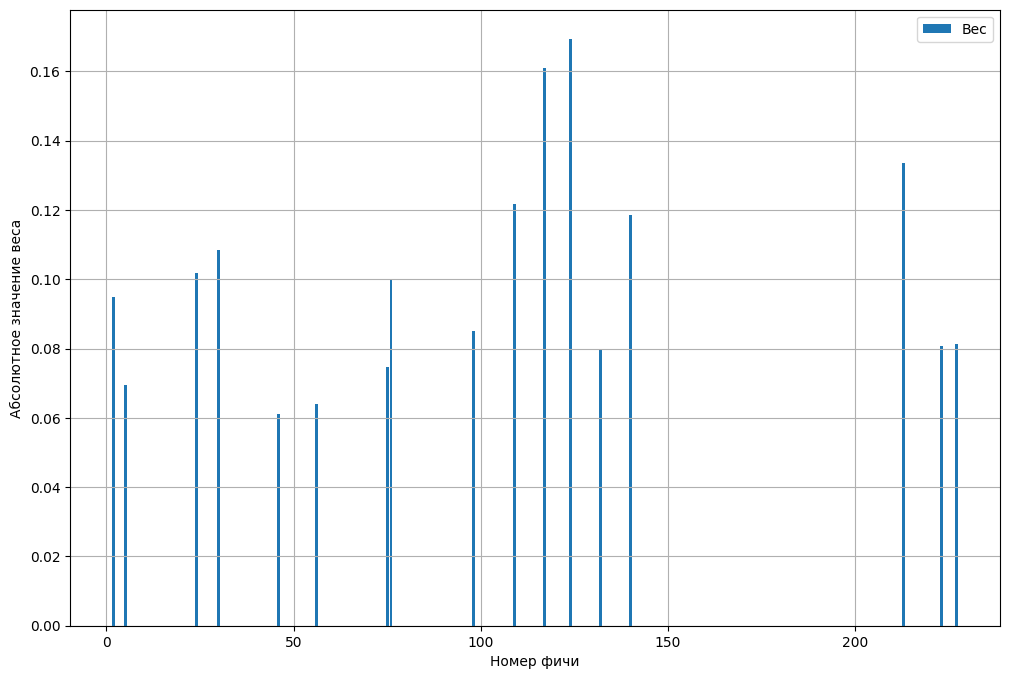

In [308]:
# your code here
weights = np.abs(logreg.coef_[0])
space = [int(f.split('_')[1]) for f in very_last_hope_features]
plt.figure(figsize=(12, 8))
plt.bar(space, weights, label = 'Вес')
plt.grid()
plt.xlabel("Номер фичи")
plt.ylabel("Абсолютное значение веса")
plt.legend()
plt.show()

In [309]:
space, weights

([140, 124, 5, 46, 213, 227, 117, 24, 76, 56, 98, 30, 132, 223, 75, 2, 109],
 array([0.11843566, 0.16931354, 0.06957086, 0.06100822, 0.13363335,
        0.08132103, 0.16100679, 0.10181758, 0.09980848, 0.06398973,
        0.08507906, 0.10830058, 0.07992532, 0.08059568, 0.07466367,
        0.09487824, 0.12179284]))

Мы помним, что по gain importance в районе 125 находилась очень важная фича. Сейчас мы знаем, что это 124 фича и что у неё наибольший вес в нашей модели, то есть её важность действительно была оправдана, а её догоняет 117 фича. Самый маленькие же веса у 46 и 56 признаков, их веса примерно одинаковые и примерно в 2.5 раза меньше веса 124 фичи.

# Бонусная часть (4 балла)

В разделе про бустинг мы обучали `LGBMClassifier` на довольно большом наборе фичей. Их количество можно сократить, при этом не теряя в качестве модели.

За начальный набор признаков можно взять все признаки (все 230) или признаки после отбора по IV.

**Ваша задача:** Отобрать признаки, подобрать оптимальные гиперпараметры и обучить `LGBMClassifier`.

Задание творческое) Можно использовать любые методы отбора признаков / оптимизации гиперпараметров.

**Чем меньше признаков, без ухудшения качества модели – тем лучше.**

In [ ]:
# your code here

Идеи для отбора признаков:

- Воспользоваться методами из модуля `sklearn.feature_selection` (точно можно попробовать RFE). Документация https://scikit-learn.org/stable/modules/feature_selection.html
<!-- - С помощью `BorutaPy` из библиотеки `boruta` (https://towardsdatascience.com/simple-example-using-boruta-feature-selection-in-python-8b96925d5d7a – статья может помочь разобраться с запуском алгоритма (мб не откроется без vpn)) -->
- permutation importance и elimination по нему (https://scikit-learn.org/stable/modules/permutation_importance.html)
- попробовать использовать shap-values

In [ ]:
# your answere here